# 01 — Data Understanding

**Question métier :** combien de temps les véhicules d'urgence perdent-ils aux feux aujourd'hui, et qu'est-ce qui explique ces pertes ?

Les données sont produites par SUMO avec le **système actuel** : feux à cycle fixe de 90 s, sans aucune priorité. 30 scénarios aléatoires sur le carrefour isolé + 6 scénarios sur le corridor de 3 carrefours. Régénérer : `python -m data.export_dataset`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
RAW = Path('../data/raw'); FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', palette='deep'); plt.rcParams['figure.dpi'] = 110
tables = {n: pd.read_csv(RAW / f'{n}.csv') for n in ['scenarios','lanes','trips','priority_tracks','priority_requests','signals']}

## 1. Inventaire des tables

In [2]:
pd.DataFrame([{'table': n, 'lignes': len(d), 'colonnes': d.shape[1], 'valeurs manquantes': int(d.isna().sum().sum()),
               'colonnes (extrait)': ', '.join(d.columns[:7])} for n, d in tables.items()])

,table,lignes,colonnes,valeurs manquantes,colonnes (extrait)
0,scenarios,36,7,0,"scenario, network, demand_level, n_priority, n..."
1,lanes,73896,10,0,"scenario, time, tls_id, approach, lane, vehicl..."
2,trips,14514,10,0,"scenario, vehicle_id, vtype, depart, arrival, ..."
3,priority_tracks,14821,10,10848,"scenario, time, vehicle_id, priority_class, si..."
4,priority_requests,229,13,0,"scenario, time, vehicle_id, priority_class, pr..."
5,signals,46221,5,0,"scenario, time, tls_id, phase, state"


In [3]:
tables['scenarios'].groupby('network').agg(scenarios=('scenario','count'), demande_moy=('demand_level','mean'),
    urgences=('n_priority','sum')).round(2)

,scenarios,demande_moy,urgences
network,,,
corridor,6,1.06,11
single,30,0.86,46


Les valeurs manquantes de `priority_tracks` correspondent aux véhicules qui ont déjà franchi leur dernier feu (`next_tls` vide) : elles sont **structurelles**, pas des erreurs.

## 2. Qualité des données

In [4]:
trips = tables['trips']
checks = {
  'durées négatives': int((trips.duration < 0).sum()),
  'temps perdu > durée': int((trips.time_loss > trips.duration + 1).sum()),
  'doublons (scénario, véhicule)': int(trips.duplicated(['scenario','vehicle_id']).sum()),
  'vitesses négatives (voies)': int((tables['lanes'].mean_speed < 0).sum()),
  'états de feux distincts': tables['signals'].state.nunique()}
checks

{'durées négatives': 0,
 'temps perdu > durée': 0,
 'doublons (scénario, véhicule)': 0,
 'vitesses négatives (voies)': 0,
 'états de feux distincts': 4}

In [5]:
trips.describe().round(1)

,depart,arrival,duration,route_length,waiting_time,stops,time_loss
count,14514.0,14514.0,14514.0,14514.0,14514.0,14514.0,14514.0
mean,423.9,509.7,85.8,801.7,17.4,0.9,26.8
std,242.9,245.4,33.1,161.5,21.3,0.9,25.5
min,0.0,43.0,31.0,489.9,0.0,0.0,0.6
25%,217.0,302.0,63.0,793.4,0.0,0.0,4.6
50%,424.0,520.0,78.0,794.9,10.0,1.0,21.9
75%,629.0,715.0,101.0,794.9,32.0,1.0,42.8
max,899.0,1069.0,482.0,1194.9,374.0,13.0,425.4


## 3. Temps perdu par type de véhicule (système actuel)

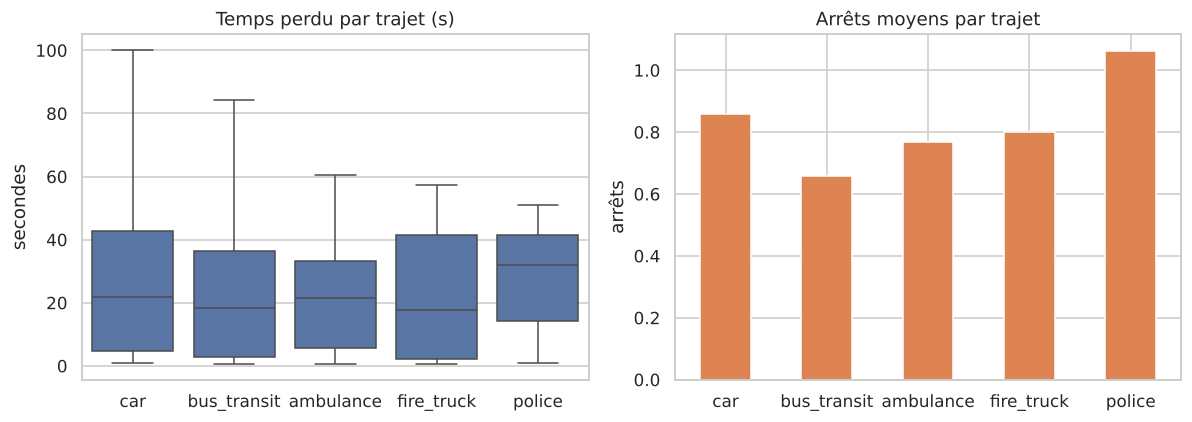

,time_loss,waiting_time,stops
vtype,,,
car,26.9,17.5,0.9
bus_transit,22.3,14.7,0.7
ambulance,26.6,15.6,0.8
fire_truck,22.2,14.3,0.8
police,31.8,23.6,1.1


In [6]:
order = ['car','bus_transit','ambulance','fire_truck','police']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=trips, x='vtype', y='time_loss', order=order, ax=ax[0], showfliers=False)
ax[0].set(title='Temps perdu par trajet (s)', xlabel='', ylabel='secondes')
trips.groupby('vtype').stops.mean().reindex(order).plot.bar(ax=ax[1], color=sns.color_palette()[1], rot=0)
ax[1].set(title='Arrêts moyens par trajet', xlabel='', ylabel='arrêts')
plt.tight_layout(); plt.savefig(FIG / 'du_time_loss_by_type.png'); plt.show()
trips.groupby('vtype')[['time_loss','waiting_time','stops']].mean().reindex(order).round(1)

**Constat clé :** avec des feux à cycle fixe, une ambulance perd autant de temps qu'une voiture ordinaire (≈ 27 s) et s'arrête presque une fois par trajet. Les feux ne savent pas qu'elle est prioritaire.

## 4. Exemple : une ambulance bloquée au rouge

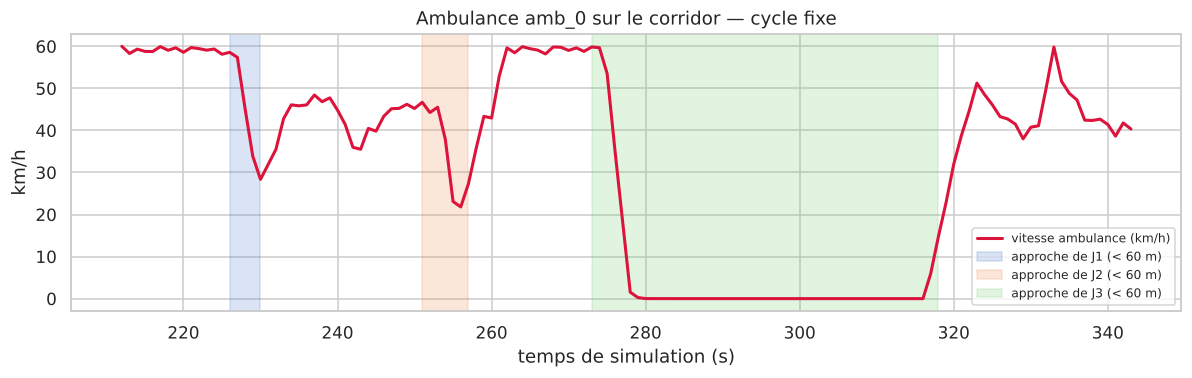

In [7]:
tr = tables['priority_tracks']; sig = tables['signals']
amb = tr[(tr.scenario=='S2_urgence_0') & (tr.vehicle_id=='amb_0')]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(amb.time, amb.speed * 3.6, color='crimson', lw=2, label='vitesse ambulance (km/h)')
for tls, col in zip(['J1','J2','J3'], sns.color_palette('muted', 3)):
    near = amb[(amb.next_tls == tls) & (amb.dist_to_tls < 60)]
    if len(near): ax.axvspan(near.time.min(), near.time.max(), color=col, alpha=.2, label=f'approche de {tls} (< 60 m)')
ax.set(xlabel='temps de simulation (s)', ylabel='km/h', title='Ambulance amb_0 sur le corridor — cycle fixe')
ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.savefig(FIG / 'du_ambulance_speed.png'); plt.show()

La vitesse tombe à zéro à l'approche d'au moins un carrefour : c'est ce temps d'arrêt que le système doit supprimer.

## 5. Files d'attente dans le temps (corridor, congestion)

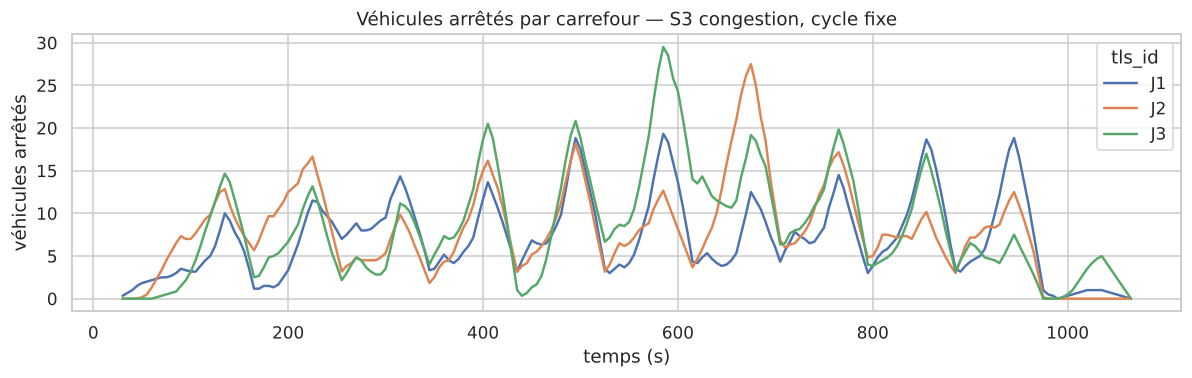

In [8]:
lanes = tables['lanes']
q = lanes[lanes.scenario=='S3_congestion_0'].groupby(['time','tls_id']).halting.sum().unstack()
ax = q.rolling(6).mean().plot(figsize=(11, 3.6), lw=1.6)
ax.set(title='Véhicules arrêtés par carrefour — S3 congestion, cycle fixe', xlabel='temps (s)', ylabel='véhicules arrêtés')
plt.tight_layout(); plt.savefig(FIG / 'du_queues_corridor.png'); plt.show()

## 6. Demande et attente

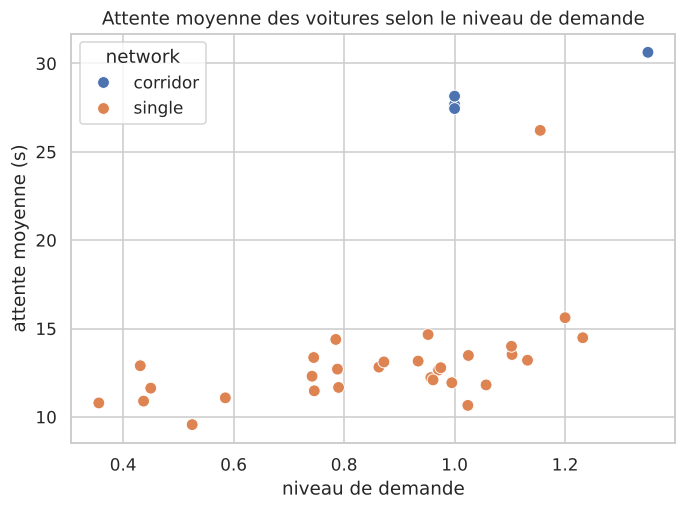

corrélation (Spearman) demande / attente : 0.61


In [9]:
tri = trips.merge(tables['scenarios'], on='scenario')
agg = tri[tri.vtype=='car'].groupby(['scenario','network','demand_level']).waiting_time.mean().reset_index()
ax = sns.scatterplot(data=agg, x='demand_level', y='waiting_time', hue='network', s=60)
ax.set(title='Attente moyenne des voitures selon le niveau de demande', xlabel='niveau de demande', ylabel='attente moyenne (s)')
plt.tight_layout(); plt.savefig(FIG / 'du_demand_vs_wait.png'); plt.show()
print('corrélation (Spearman) demande / attente :', round(agg.demand_level.corr(agg.waiting_time, method='spearman'), 2))

## 7. Répartition des files par approche (carrefour isolé)

In [10]:
single = lanes[lanes.tls_id=='C']
pv = single.groupby(['approach']).agg(arrets_moy=('halting','mean'), occupation_moy=('occupancy','mean'), vitesse_moy=('mean_speed','mean'))
pv.round(2)

,arrets_moy,occupation_moy,vitesse_moy
approach,,,
E,0.82,0.04,9.96
N,0.67,0.03,10.06
S,0.71,0.03,9.96
W,0.72,0.03,10.01


## 8. Demandes de priorité (V2I)

In [11]:
rq = tables['priority_requests']
rq['statut'] = np.select([rq.valid_request, ~rq.siren_on & (rq.priority_class!='TRANSIT'), ~rq.confirmed],
                         ['valide', 'sirène éteinte', 'non confirmée'], 'bus à l\'heure')
tab = pd.crosstab(rq.priority_class, rq.statut); tab

statut,bus à l'heure,non confirmée,sirène éteinte,valide
priority_class,,,,
EMERGENCY_MEDICAL,0,4,0,35
FIRE,0,0,0,12
POLICE,0,0,4,16
TRANSIT,93,0,0,65


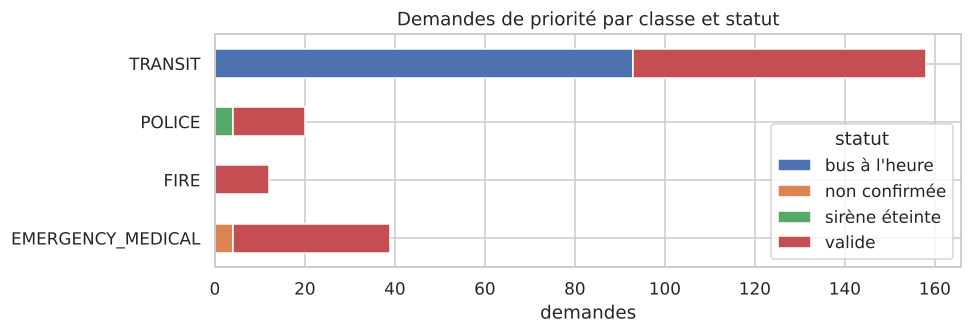

In [12]:
ax = tab.plot.barh(stacked=True, figsize=(9, 3.2))
ax.set(title='Demandes de priorité par classe et statut', xlabel='demandes', ylabel='')
plt.tight_layout(); plt.savefig(FIG / 'du_requests.png'); plt.show()

## 9. Conclusions pour la modélisation

1. **Problème confirmé :** au cycle fixe, les urgences perdent ≈ autant de temps que le trafic ordinaire.
2. **Variables utiles** pour l'état de PPO : files et densités par voie (elles expliquent l'attente), phase courante et durée, occupation en aval, et le contexte de priorité (approche, ETA).
3. **Toutes les demandes ne sont pas valables :** sirènes éteintes, demandes non confirmées, bus à l'heure. Le système doit filtrer avant d'agir (rôle du coordinateur et du Safety Controller).
4. **Forte variabilité selon la demande :** l'entraînement doit couvrir un large intervalle de niveaux de trafic, et l'évaluation doit se faire sur des graines non vues.